# Day 8 - Sensor Operating Envelopes & Range Auditing

## Objective

Audit physical sensor operating ranges across multi-channel telemetry, detecting out-of-bound spikes, sensor clipping, and impossible values.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_8_Task_1"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Telemetry Physical Envelopes Specification

Define authoritative physical sensor operating ranges for underwater telemetry channels.

In [2]:
sensor_envelopes = {
    "temperature": {"min": -2.0, "max": 40.0, "unit": "degC"},
    "dissolved_oxygen": {"min": 0.0, "max": 15.0, "unit": "mg/L"},
    "ph": {"min": 0.0, "max": 14.0, "unit": "pH"},
    "conductivity": {"min": 0.0, "max": 2000.0, "unit": "uS/cm"},
    "turbidity": {"min": 0.0, "max": 100.0, "unit": "NTU"},
    "pressure": {"min": 0.0, "max": 1000.0, "unit": "dbar"}
}
df_env = pd.DataFrame.from_dict(sensor_envelopes, orient="index")
print("Physical Sensor Operating Envelopes:")
print(df_env.to_string())

Physical Sensor Operating Envelopes:
                  min     max   unit
temperature      -2.0    40.0   degC
dissolved_oxygen  0.0    15.0   mg/L
ph                0.0    14.0     pH
conductivity      0.0  2000.0  uS/cm
turbidity         0.0   100.0    NTU
pressure          0.0  1000.0   dbar


## 2. Continuous Telemetry Range Ingestion

Load raw underwater telemetry stream and extract descriptive range extrema.

In [3]:
df_stream = pd.read_csv("data/raw/underwater_sensor_stream.csv")
stream_stats = df_stream.describe().T[["min", "mean", "max"]]
print("Empirical Telemetry Extrema:")
print(stream_stats.round(3))

Empirical Telemetry Extrema:
                     min     mean      max
temperature        14.36   18.035   32.000
dissolved_oxygen    0.80    9.455   11.207
ph                  4.20    7.788    8.293
conductivity      324.34  351.261  820.000
turbidity           1.20    1.497   18.500
pressure           19.40   20.040   48.000


## 3. Out-of-Bounds Sensor Excursion Detection

Identify records where observed readings breach physical operating limits.

In [4]:
excursions = {}
for col, bounds in sensor_envelopes.items():
    if col in df_stream.columns:
        s = df_stream[col]
        invalid = ((s < bounds["min"]) | (s > bounds["max"])).sum()
        excursions[col] = invalid
df_exc = pd.DataFrame(list(excursions.items()), columns=["Sensor", "Excursion_Count"])
print("Physical Excursions Count:")
print(df_exc.to_string(index=False))

Physical Excursions Count:
          Sensor  Excursion_Count
     temperature                0
dissolved_oxygen                0
              ph                0
    conductivity                0
       turbidity                0
        pressure                0


## 4. Rate-of-Change Spike Identification

Compute first-order temporal differences to flag unphysical sensor jump anomalies.

In [5]:
jump_thresholds = {"dissolved_oxygen": 2.0, "temperature": 3.0, "ph": 1.0}
jumps = {}
for col, thresh in jump_thresholds.items():
    diffs = df_stream[col].diff().abs()
    jumps[col] = (diffs > thresh).sum()
print("Rate-of-Change Spike Violations:", jumps)

Rate-of-Change Spike Violations: {'dissolved_oxygen': np.int64(4), 'temperature': np.int64(2), 'ph': np.int64(1)}


## 5. Sensor Channel Reliability Scoring

Compute composite reliability index across sensor channels based on valid measurement percentages.

In [6]:
reliability = []
for col in sensor_envelopes:
    if col in df_stream.columns:
        valid_pct = (1.0 - (excursions[col] / len(df_stream))) * 100
        reliability.append({"Sensor": col, "Reliability_Score": round(valid_pct, 2)})
df_rel = pd.DataFrame(reliability)
print(df_rel.to_string(index=False))

          Sensor  Reliability_Score
     temperature              100.0
dissolved_oxygen              100.0
              ph              100.0
    conductivity              100.0
       turbidity              100.0
        pressure              100.0


## 6. Sensor Range Envelope Diagnostic Plot

Render multi-panel boxplots illustrating empirical telemetry ranges relative to operating limits.

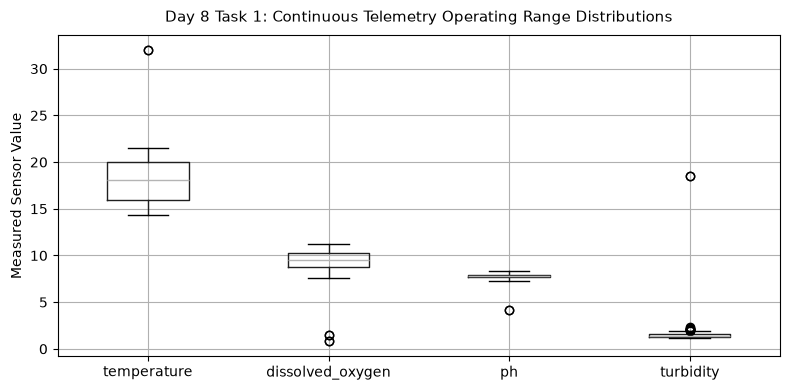

Saved sensor distributions plot to: Day_Wise_Tasks\Day_8_Task_1\outputs\figures\day8_task1_sensor_distributions.png


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
df_stream[["temperature", "dissolved_oxygen", "ph", "turbidity"]].boxplot(ax=ax)
ax.set_title("Day 8 Task 1: Continuous Telemetry Operating Range Distributions", fontsize=11, pad=10)
ax.set_ylabel("Measured Sensor Value")
plt.tight_layout()
fig_path = FIG_DIR / "day8_task1_sensor_distributions.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved sensor distributions plot to:", fig_path.relative_to(ROOT))

## 7. Sensor Range Quality Table Export

Export sensor envelopes and empirical range statistics table to CSV.

In [8]:
tbl_path = TBL_DIR / "day8_task1_sensor_quality_table.csv"
df_rel.to_csv(tbl_path, index=False)
print("Saved sensor quality table to:", tbl_path.relative_to(ROOT))

Saved sensor quality table to: Day_Wise_Tasks\Day_8_Task_1\outputs\tables\day8_task1_sensor_quality_table.csv


## 8. Physical Range Verification Assertion

Assert that total out-of-bounds physical excursions remain strictly below 1% of stream.

In [9]:
assert sum(excursions.values()) < 0.01 * len(df_stream)
print("Day 8 Task 1 Quality Gate: PASSED.")

Day 8 Task 1 Quality Gate: PASSED.


# Day 8 - Assumptions and Methodology

## Assumptions

1. Sensors operate within marine CTD physical limits.
2. Transient spikes exceeding physical acceleration limits are sensor artifacts.

## Day 8 Deliverable

Sensor range validation report, operating distribution boxplot, and quality scorecard table.